# FDA PMA data import

Downloads the FDA Premarket Approval (PMA) database, cleans it and saves two tables:

| file | one row per | use |
|---|---|---|
| `data/processed/pma_records.csv` | decision (original approval or supplement) | full history and text |
| `data/processed/pma_devices.csv` | PMA number (a device approval) | candidate network nodes |

Source: [FDA PMA approvals](https://www.fda.gov/medical-devices/device-approvals-and-clearances/pma-approvals), file `pma.zip`, replaced by FDA about once a month.

Part 2 adds FDA adverse event reports and limits the project to 2020-2025.

A PMA is the approval for a high-risk (class III) device. Later changes to that device are filed as **supplements**, so most rows describe changes to a device, not new devices.

In [1]:
import csv
import hashlib
import io
import json
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

PMA_URL = "https://www.accessdata.fda.gov/premarket/ftparea/pma.zip"

RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
ZIP_PATH = RAW_DIR / "pma.zip"
INFO_PATH = RAW_DIR / "pma_download_info.json"

# Set to True to fetch FDA's latest file. Results can then change, so keep it False once analysis starts.
REFRESH = False

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 1. Download

The file is downloaded once and reused. Each download records its date and checksum, so the paper can state exactly which version was used.

In [2]:
if REFRESH or not ZIP_PATH.exists():
    request = urllib.request.Request(PMA_URL, headers={"User-Agent": "Mozilla/5.0 (DTU course project)"})
    with urllib.request.urlopen(request, timeout=120) as response:
        ZIP_PATH.write_bytes(response.read())

    with zipfile.ZipFile(ZIP_PATH) as zf:
        member = zf.infolist()[0]
    INFO_PATH.write_text(json.dumps({
        "url": PMA_URL,
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "fda_file_date": datetime(*member.date_time).isoformat(),
        "sha256": hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest(),
    }, indent=2))

print(INFO_PATH.read_text())

{
  "url": "https://www.accessdata.fda.gov/premarket/ftparea/pma.zip",
  "downloaded_at_utc": "2026-11-04T09:50:03+00:00",
  "fda_file_date": "2026-11-02T00:40:58",
  "sha256": "80b670581d2963a8665013f9c5bf2840eb758fe830efb0ffb58c0da4aa53c79c"
}


## 2. Parse

FDA's [file description](https://www.fda.gov/medical-devices/medical-device-databases/file-description-cdrh-releasable-approved-pmas) is out of date, so these settings come from inspecting the file itself:

- **Encoding is cp1252, not UTF-8.** Reading it as UTF-8 fails on characters such as ® and ™.
- **Quoting must be off.** Fields contain 988 literal `"` characters, and treating them as quotes could merge rows.
- **NUL bytes are removed.** There are 308 of them and they carry no meaning.
- **Dates are `mm/dd/yyyy`**, not `mm-dd-yyyy` as documented.
- **Every value is read as text**, so ZIP codes keep their leading zeros.

In [3]:
with zipfile.ZipFile(ZIP_PATH) as zf:
    raw_bytes = zf.read("pma.txt")

raw = pd.read_csv(
    io.BytesIO(raw_bytes.replace(b"\0", b"")),
    sep="|",
    encoding="cp1252",
    quoting=csv.QUOTE_NONE,
    dtype=str,
    keep_default_na=False,
)

print(raw.shape)
raw.head(3)

(57487, 22)


,PMANUMBER,SUPPLEMENTNUMBER,APPLICANT,STREET_1,STREET_2,CITY,STATE,ZIP,ZIP_EXT,GENERICNAME,...,ADVISORYCOMMITTEE,SUPPLEMENTTYPE,SUPPLEMENTREASON,REVIEWGRANTEDYN,DATERECEIVED,DECISIONDATE,DOCKETNUMBER,FEDREGNOTICEDATE,DECISIONCODE,AOSTATEMENT
0,P890055,S029,Intera Oncology,"180 Wells Ave., Suite 300a",,Newton,MA,02459,,"Pump, infusion, implanted, programmable",...,HO,Normal 180 Day Track No User Fee,Postapproval Study Protocol - OSB,N,01/18/2011,03/15/2011,,,APPR,APPROVAL OF THE POST-APPROVAL STUDY PROTOCOL.
1,P890055,S030,Intera Oncology,"180 Wells Ave., Suite 300a",,Newton,MA,02459,,"Pump, infusion, implanted, programmable",...,HO,Normal 180 Day Track No User Fee,Postapproval Study Protocol - OSB,N,01/18/2011,03/15/2011,,,APPR,APPROVAL OF THE POST-APPROVAL PROTOCOL.
2,P890055,S031,Intera Oncology,"180 Wells Ave., Suite 300a",,Newton,MA,02459,,"Pump, infusion, implanted, programmable",...,HO,Normal 180 Day Track,Change Design/Components/Specifications/Material,N,01/18/2011,02/12/2013,,,APPR,APPROVAL FOR MODIFICATIONS TO THE MEDSTREAM RE...


## 3. Clean

- Columns get readable names, and `zip_ext` is dropped because it is always empty.
- Whitespace is stripped. Empty strings and the literal text `undefined` become missing values.
- `is_original` marks the original approval. Supplements carry a supplement number such as `S029`.
- `review_days` is the time from receipt to decision.

Applicant names and the text itself are **not** normalised here, because those choices belong to the analysis. See the caveats at the end.

In [4]:
COLUMN_NAMES = {
    "PMANUMBER": "pma_number",
    "SUPPLEMENTNUMBER": "supplement_number",
    "APPLICANT": "applicant",
    "STREET_1": "street_1",
    "STREET_2": "street_2",
    "CITY": "city",
    "STATE": "state",
    "ZIP": "zip",
    "GENERICNAME": "generic_name",
    "TRADENAME": "trade_name",
    "PRODUCTCODE": "product_code",
    "ADVISORYCOMMITTEE": "advisory_committee",
    "SUPPLEMENTTYPE": "supplement_type",
    "SUPPLEMENTREASON": "supplement_reason",
    "REVIEWGRANTEDYN": "expedited_review",
    "DATERECEIVED": "date_received",
    "DECISIONDATE": "decision_date",
    "DOCKETNUMBER": "docket_number",
    "FEDREGNOTICEDATE": "fed_reg_notice_date",
    "DECISIONCODE": "decision_code",
    "AOSTATEMENT": "ao_statement",
}

records = raw[list(COLUMN_NAMES)].rename(columns=COLUMN_NAMES)
records = records.apply(lambda col: col.str.strip())

records["is_original"] = records["supplement_number"] == ""
records = records.replace({"": pd.NA, "undefined": pd.NA})

for col in ["date_received", "decision_date", "fed_reg_notice_date"]:
    records[col] = pd.to_datetime(records[col], format="%m/%d/%Y")

records["review_days"] = (records["decision_date"] - records["date_received"]).dt.days
records["decision_year"] = records["decision_date"].dt.year

records = records.sort_values(["decision_date", "pma_number", "supplement_number"]).reset_index(drop=True)
records.info()

<class 'pandas.DataFrame'>
RangeIndex: 57487 entries, 0 to 57486
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   pma_number           57487 non-null  str           
 1   supplement_number    56003 non-null  str           
 2   applicant            57487 non-null  str           
 3   street_1             57357 non-null  str           
 4   street_2             9327 non-null   str           
 5   city                 57467 non-null  str           
 6   state                54153 non-null  str           
 7   zip                  57046 non-null  str           
 8   generic_name         56716 non-null  str           
 9   trade_name           57487 non-null  str           
 10  product_code         56716 non-null  str           
 11  advisory_committee   57487 non-null  str           
 12  supplement_type      54118 non-null  str           
 13  supplement_reason    53017 non-null  str  

## 4. Build the device table

One row per PMA number. Some fields change during a device's life (for example the applicant, after an acquisition), so the first and latest values are kept. `n_unique_statements` counts distinct texts, because FDA often repeats one statement across many supplements.

In [5]:
grouped = records.sort_values("decision_date").groupby("pma_number")

devices = grouped.agg(
    first_applicant=("applicant", "first"),
    latest_applicant=("applicant", "last"),
    n_applicant_names=("applicant", "nunique"),
    trade_name=("trade_name", "first"),
    generic_name=("generic_name", "first"),
    product_code=("product_code", "first"),
    advisory_committee=("advisory_committee", "first"),
    has_original_record=("is_original", "any"),
    n_records=("is_original", "size"),
    first_decision=("decision_date", "min"),
    latest_decision=("decision_date", "max"),
    n_unique_statements=("ao_statement", "nunique"),
).reset_index()

devices["n_supplements"] = devices["n_records"] - devices["has_original_record"].astype(int)
devices.head(3)

,pma_number,first_applicant,latest_applicant,n_applicant_names,trade_name,generic_name,product_code,advisory_committee,has_original_record,n_records,first_decision,latest_decision,n_unique_statements,n_supplements
0,N10389,"ETHICON, Inc.","ETHICON, Inc.",1,"ABSORBABLE SURGICAL SUTURE, USP","Suture, absorbable, natural",GAL,SU,False,18,1981-01-06,1987-10-05,0,18
1,N11397,"ETHICON, Inc.","ETHICON, Inc.",1,"SILK SUTURE, NONABSORBABLE SURG. SUTURE, USP","Suture, nonabsorbable, silk",GAP,SU,False,16,1981-01-06,1990-03-20,0,16
2,N12159,"ETHICON, Inc.","ETHICON, Inc.",1,SURGICEL BRAND ABSORBABLE HEMOSTAT,"Agent, absorbable hemostatic, non-collagen based",LMG,SU,True,121,1960-10-14,2026-07-28,109,120


## 5. Check the import

These checks stop the notebook if a future FDA file changes shape or a parsing step drops rows.

In [6]:
n_raw_lines = raw_bytes.count(b"\r\n") - 1

assert raw.shape[1] == 22, "FDA changed the number of columns"
assert len(records) == n_raw_lines, "rows were lost or merged while parsing"
assert not records.duplicated(["pma_number", "supplement_number"]).any(), "duplicate decision"
assert records["pma_number"].notna().all() and records["applicant"].notna().all()
assert records["decision_date"].notna().all() and records["date_received"].notna().all()
assert (records["review_days"] >= 0).all(), "decision before receipt"
assert records["pma_number"].str.fullmatch(r"[PN]\d{4,6}").all(), "unexpected PMA number"
assert len(devices) == records["pma_number"].nunique()
assert devices["n_records"].sum() == len(records)

print("All checks passed")

All checks passed


In [7]:
summary = {
    "decisions": len(records),
    "devices (PMA numbers)": len(devices),
    "devices with no original record": (~devices["has_original_record"]).sum(),
    "distinct applicant names": records["applicant"].nunique(),
    "product codes": records["product_code"].nunique(),
    "first decision": records["decision_date"].min().date(),
    "latest decision": records["decision_date"].max().date(),
    "decisions with no statement": records["ao_statement"].isna().sum(),
    "distinct statements": records["ao_statement"].nunique(),
    "median statement length (characters)": int(records["ao_statement"].str.len().median()),
}
pd.Series(summary, name="value").to_frame()

,value
decisions,57487
devices (PMA numbers),1754
devices with no original record,270
distinct applicant names,821
product codes,481
first decision,1960-10-14
latest decision,2026-10-30
decisions with no statement,6709
distinct statements,32094
median statement length (characters),102


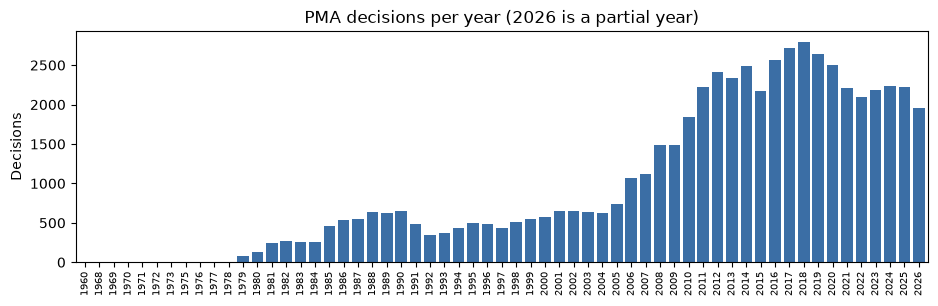

In [8]:
records["decision_year"].value_counts().sort_index().plot(
    kind="bar", figsize=(11, 3), width=0.8, color="#3b6ea5",
    title="PMA decisions per year (2026 is a partial year)", xlabel="", ylabel="Decisions",
).tick_params(axis="x", labelsize=7);

## 6. Save

In [9]:
records.to_csv(PROCESSED_DIR / "pma_records.csv", index=False)
devices.to_csv(PROCESSED_DIR / "pma_devices.csv", index=False)

check = pd.read_csv(PROCESSED_DIR / "pma_records.csv", dtype=str, keep_default_na=False, na_values=[""])
assert len(check) == len(records), "saved file does not read back to the same rows"

print(f"Saved {len(records):,} decisions and {len(devices):,} devices to {PROCESSED_DIR}/")

Saved 57,487 decisions and 1,754 devices to data/processed/


## Caveats for the analysis

1. **Applicant names need resolving before any company network.** One firm appears under many names, such as `Medtronic, Inc.` and `Medtronic Vascular, Inc.`, or `Boston Scientific Corp` and `Boston Scientific`. The course asks us to check name resolution ourselves.
2. **There is no built-in network.** Only 94 PMA-to-PMA references appear in the statements, so edges have to be built or brought in from another source.
3. **Statements are short and often repeated.** The median is 102 characters and only 32,094 of the 50,778 non-empty statements are distinct, so counting documents naively overweights repeated text.
4. **Text coverage depends on era.** The median statement length is 0 for decisions before 2000, because most of those statements are empty. Old text is also all capitals.
5. **Some characters are damaged in FDA's file.** Apostrophes often appear as `¿` or `?`, as in `GORE¿S`.
6. **270 devices have no original record.** They appear only through supplements, so their `first_decision` is the first supplement, not the approval date.
7. **Only `P` numbers follow the modern format.** `N` numbers are older approvals that were moved into the PMA system.

# Part 2: Adverse events, 2020-2025

This part adds FDA adverse event reports (the MAUDE database) and limits the project to 2020-2025.

Run `python import_adverse_events.py` first. It downloads the openFDA bulk files and keeps reports linked to PMA devices in `data/raw/maude_parts/`. That takes about an hour and only has to happen once. The cells below clean those parts and save:

| file | one row per | use |
|---|---|---|
| `data/processed/maude_reports.csv.gz` | adverse event report | severity, problems, dates |
| `data/processed/maude_text.csv.gz` | adverse event report | report text, kept apart because it is large |
| `data/processed/pma_records_2020_2025.csv` | FDA decision in 2020-2025 | device changes in the study period |
| `data/processed/pma_devices_2020_2025.csv` | device active in 2020-2025 | network nodes, with report counts |

**Which reports are used:** only those carrying a real PMA number. The parts also hold reports with a blank number and a PMA product code, but these are not used. Most are dental implants that have no PMA number at all, or insulin pumps that cannot be tied to one PMA.

**Which devices are in scope:** any device with an FDA decision or an adverse event report in 2020-2025. Older devices still in use are included, because they can still cause harm.

## 7. Load the reports

In [10]:
import gzip
import re
from collections import Counter

PARTS_DIR = RAW_DIR / "maude_parts"
FIRST_DATE, LAST_DATE = "2020-01-01", "2025-12-31"

# Reports received in 2020-2025 for all devices, from the openFDA API on 4 Nov 2026
FDA_REPORTS_2020_2025 = 14_393_654

REPORT_COLUMNS = [
    "mdr_report_key", "report_number", "date_received", "date_of_event", "event_type",
    "pma_number", "supplement_number", "product_code", "brand_name", "generic_name",
    "n_devices", "report_source", "manufacturer_report_type", "patient_age", "patient_sex",
    "product_problems", "patient_problems", "patient_outcomes",
]


def clean_text(text):
    """Remove FDA redaction marks like (B)(6), repair damaged apostrophes, tidy whitespace."""
    return (
        text.fillna("")
        .str.replace(r"\(B\)\(\d\)", " ", regex=True, flags=re.IGNORECASE)
        .str.replace("¿", "'", regex=False)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )




manifest = pd.read_csv(PARTS_DIR / "manifest.csv")
part_paths = sorted(PARTS_DIR.glob("*.csv.gz"))

link_counts = Counter()
frames = []
for path in part_paths:
    part = pd.read_csv(path, dtype=str, keep_default_na=False, na_values=[""])
    link_counts.update(part["link_source"])
    part = part[part["link_source"] == "pma_number"].copy()

    description = clean_text(part["event_description"])
    part["text_chars"] = description.str.len()
    part["text_id"] = description.map(hash)
    frames.append(part[REPORT_COLUMNS + ["text_chars", "text_id"]])

reports = pd.concat(frames, ignore_index=True)
del frames

print(f"{len(part_paths)} files, {manifest['records_read'].sum():,} reports read")
print(dict(link_counts))
print(f"Reports with a PMA number: {len(reports):,}")

165 files, 14,393,654 reports read
{'pma_number': 2423241, 'product_code': 1760857}
Reports with a PMA number: 2,423,241


## 8. Clean the reports

- **Outcome letters are decoded.** Some outcomes are single letters, so `R` becomes `Required Intervention`. The letters were checked against `event_type`: 93% of reports marked `D` are recorded as deaths.
- **Reports that match no device are dropped.** Their numbers are mistyped or cut short, such as `P01004`.
- **Older versions are dropped, cautiously.** A report is removed only if a later report has the same report number and device, and either identical text or the earlier one has no text. Report number alone is not enough, because one manufacturer reuses numbers for different events.
- **`is_repeat_text` flags reports whose text already appeared for that device.** They are real, separate reports, so they stay in. Text analysis should skip them, or a few templates will dominate.

In [11]:
OUTCOME_CODES = {
    "D": "Death",
    "L": "Life Threatening",
    "H": "Hospitalization",
    "S": "Disability",
    "R": "Required Intervention",
    "O": "Other",
    "C": "Congenital Anomaly",
}


def decode_outcomes(value):
    names = [OUTCOME_CODES.get(v, v) for v in value.split("; ")]
    return "; ".join(dict.fromkeys(names))


outcomes = reports["patient_outcomes"]
reports["patient_outcomes"] = outcomes.map({v: decode_outcomes(v) for v in outcomes.dropna().unique()})

for name in ["Death", "Life Threatening", "Hospitalization", "Disability", "Required Intervention"]:
    column = "outcome_" + name.lower().replace(" ", "_")
    reports[column] = reports["patient_outcomes"].str.contains(name, regex=False, na=False)

reports["date_received"] = pd.to_datetime(reports["date_received"], format="%Y%m%d")
reports["date_of_event"] = pd.to_datetime(reports["date_of_event"], format="%Y%m%d", errors="coerce")
reports["year_received"] = reports["date_received"].dt.year
reports["n_devices"] = reports["n_devices"].astype(int)

n_before = len(reports)
reports = reports[reports["pma_number"].isin(devices["pma_number"])]
n_unmatched = n_before - len(reports)

reports = reports.sort_values(["date_received", "mdr_report_key"], key=lambda col: col.astype(str)).reset_index(drop=True)
has_text = reports["text_chars"] > 0
same_report = ["report_number", "pma_number"]
older_same_text = has_text & reports.duplicated(same_report + ["text_id"], keep="last")
older_no_text = ~has_text & reports.duplicated(same_report, keep="last")
reports = reports[~(older_same_text | older_no_text)].reset_index(drop=True)
n_older_versions = int((older_same_text | older_no_text).sum())

has_text = reports["text_chars"] > 0
reports["is_repeat_text"] = has_text & reports.duplicated(["pma_number", "text_id"], keep="first")

print(f"No matching device: {n_unmatched:,}")
print(f"Older versions dropped: {n_older_versions:,}")
print(f"Reports kept: {len(reports):,}")
print(f"Repeated text: {reports['is_repeat_text'].sum():,} ({reports['is_repeat_text'].mean():.1%})")

No matching device: 687
Older versions dropped: 190
Reports kept: 2,422,364
Repeated text: 542,137 (22.4%)


## 9. Limit to 2020-2025

`harm_share` is the share of a device's reports involving a death or injury. Use this rather than raw counts, because the data does not say how many of each device were used, so a high count may only mean the device sells well.

In [12]:
records_window = records[records["decision_date"].between(FIRST_DATE, LAST_DATE)]

severity = (
    pd.crosstab(reports["pma_number"], reports["event_type"])
    .reindex(columns=["Death", "Injury", "Malfunction"], fill_value=0)
    .rename(columns={"Death": "n_deaths", "Injury": "n_injuries", "Malfunction": "n_malfunctions"})
)
severity["n_reports"] = reports.groupby("pma_number").size()
severity["n_unique_report_texts"] = (reports["text_chars"] > 0).groupby(reports["pma_number"]).sum() \
    - reports["is_repeat_text"].groupby(reports["pma_number"]).sum()
severity = severity.reset_index()

decisions_window = records_window.groupby("pma_number").size().rename("n_decisions_2020_2025").reset_index()

active = set(records_window["pma_number"]) | set(reports["pma_number"])
devices_window = (
    devices[devices["pma_number"].isin(active)]
    .merge(decisions_window, on="pma_number", how="left")
    .merge(severity, on="pma_number", how="left")
)

count_columns = ["n_decisions_2020_2025", "n_deaths", "n_injuries", "n_malfunctions", "n_reports", "n_unique_report_texts"]
devices_window[count_columns] = devices_window[count_columns].fillna(0).astype(int)
devices_window["death_share"] = devices_window["n_deaths"] / devices_window["n_reports"].where(devices_window["n_reports"] > 0)
devices_window["harm_share"] = (
    (devices_window["n_deaths"] + devices_window["n_injuries"]) / devices_window["n_reports"].where(devices_window["n_reports"] > 0)
)

print(f"Decisions in window: {len(records_window):,}")
print(f"Devices in scope: {len(devices_window):,}")

Decisions in window: 13,436
Devices in scope: 920


## 10. Check the import

In [13]:
assert len(part_paths) == len(manifest) == manifest["part"].nunique(), "a file is missing"
assert manifest["records_read"].sum() == FDA_REPORTS_2020_2025, "reports read do not match FDA's total"
assert manifest["fda_export_date"].nunique() == 1, "files come from different FDA exports"
assert not reports["mdr_report_key"].duplicated().any(), "duplicate report"
assert reports["date_received"].between(FIRST_DATE, LAST_DATE).all(), "report outside the study period"
assert reports["pma_number"].isin(devices["pma_number"]).all()
assert records_window["decision_date"].dt.year.between(2020, 2025).all()
assert not devices_window["pma_number"].duplicated().any()
assert devices_window["n_reports"].sum() == len(reports), "reports lost when counting per device"
assert devices_window["n_decisions_2020_2025"].sum() == len(records_window), "decisions lost"
assert devices_window["harm_share"].dropna().between(0, 1).all()

print("All checks passed")

All checks passed


In [14]:
by_year = pd.crosstab(reports["year_received"], reports["event_type"]).reindex(columns=["Death", "Injury", "Malfunction"], fill_value=0)
by_year["Total"] = by_year.sum(axis=1)
by_year

event_type,Death,Injury,Malfunction,Total
year_received,,,,
2020,6110,187542,189319,382971
2021,6052,176913,197303,380268
2022,5906,192996,109334,308236
2023,8530,208124,205240,421894
2024,8754,219819,230223,458796
2025,8661,216742,244796,470199


In [15]:
counts = devices_window["n_reports"]
top_ten_share = counts.nlargest(10).sum() / counts.sum()

summary = {
    "reports": len(reports),
    "deaths": (reports["event_type"] == "Death").sum(),
    "injuries": (reports["event_type"] == "Injury").sum(),
    "malfunctions": (reports["event_type"] == "Malfunction").sum(),
    "reports with repeated text": reports["is_repeat_text"].sum(),
    "reports over 20,000 characters": (reports["text_chars"] > 20_000).sum(),
    "devices in scope": len(devices_window),
    "devices with at least one report": (counts > 0).sum(),
    "devices with at least 100 reports": (counts >= 100).sum(),
    "devices with at least 1,000 reports": (counts >= 1_000).sum(),
    "median reports per device with reports": int(counts[counts > 0].median()),
    "share of reports from the top 10 devices": round(top_ten_share, 3),
    "distinct product problem terms": reports["product_problems"].str.split("; ").explode().nunique(),
    "distinct patient problem terms": reports["patient_problems"].str.split("; ").explode().nunique(),
}
pd.Series(summary, name="value").to_frame()

,value
reports,2422364.000
deaths,44013.000
injuries,1202136.000
malfunctions,1176215.000
reports with repeated text,542137.000
"reports over 20,000 characters",137.000
devices in scope,920.000
devices with at least one report,713.000
devices with at least 100 reports,334.000
"devices with at least 1,000 reports",152.000


In [16]:
top_devices = devices_window.nlargest(10, "n_reports")[
    ["pma_number", "latest_applicant", "trade_name", "n_reports", "n_deaths", "harm_share"]
]
top_devices

,pma_number,latest_applicant,trade_name,n_reports,n_deaths,harm_share
411,P160017,"Medtronic Minimed, Inc.",MiniMed 670G System,203612,260,0.153056
422,P160030,"Abbott Diabetes Care, Inc.",Freestyle Libre Flash Glucose Monitoring System,108707,9,0.109450
810,P930039,"Medtronic, Inc.","MEDTRONIC(R) CAPSUREFIX LEAD MODEL 4068,4067,4568",106643,1190,0.446696
294,P120005,"Dexcom, Inc.",DEXCOM G4 PLATINUM CONTIUOUS GLUCOSE MONITORIN...,101037,1,0.006295
362,P150001,Medtronic Minimed,MINIMED 630G SYSTEM WITH SMARTGUARD(TM),94713,439,0.175372
79,P020056,Allergan,NATRELLE SILICONE-FILLED BREAST IMPLANTS,82251,6,0.994565
46,P010032,ABBOTT MEDICAL,GENESIS AND EON FAMILY NEUROSTIMULATION (IPG) ...,77407,89,0.970920
44,P010030,Zoll Manufacturing Corporation,WEARABLE CARDIOVERTER DEFIBRILLATOR (WCD) 2000...,73935,1962,0.289322
108,P030053,Mentor Corp.,MEMORYGEL SILICONE GEL -FILLED BREAST IMPLANTS,54123,0,0.980101
717,P840001,Medtronic Neuromodulation,ITREL(R) TOTALLY IMPLANTABLE SPINAL CORD STIM....,52464,5,0.310289


## 11. Save

The text is written in a second pass, one file at a time, so it never has to fit in memory.

In [17]:
drop_when_saving = ["text_id"]
reports.drop(columns=drop_when_saving).to_csv(PROCESSED_DIR / "maude_reports.csv.gz", index=False)
records_window.to_csv(PROCESSED_DIR / "pma_records_2020_2025.csv", index=False)
devices_window.to_csv(PROCESSED_DIR / "pma_devices_2020_2025.csv", index=False)

repeat_flags = reports.set_index("mdr_report_key")["is_repeat_text"]
n_text_rows = 0
with gzip.open(PROCESSED_DIR / "maude_text.csv.gz", "wt", encoding="utf-8", newline="") as out:
    for path in part_paths:
        part = pd.read_csv(
            path, dtype=str, keep_default_na=False, na_values=[""],
            usecols=["mdr_report_key", "pma_number", "event_description", "manufacturer_narrative"],
        )
        part = part[part["mdr_report_key"].isin(repeat_flags.index)].copy()
        part["event_description"] = clean_text(part["event_description"])
        part["manufacturer_narrative"] = clean_text(part["manufacturer_narrative"])
        part["is_repeat_text"] = part["mdr_report_key"].map(repeat_flags)
        part.to_csv(out, index=False, header=n_text_rows == 0)
        n_text_rows += len(part)

assert n_text_rows == len(reports), "text file does not match the reports table"

saved = pd.read_csv(PROCESSED_DIR / "maude_reports.csv.gz", usecols=["mdr_report_key"], dtype=str)
assert len(saved) == len(reports), "saved file does not read back to the same rows"

print(f"Saved {len(reports):,} reports and {len(devices_window):,} devices to {PROCESSED_DIR}/")

Saved 2,422,364 reports and 920 devices to data/processed/


## Caveats for the adverse event analysis

1. **A report does not prove the device caused the harm.** It only records that a harm was reported alongside the device.
2. **Counts cannot be read as risk.** The data has no usage numbers, so compare shares such as `harm_share`, not raw report counts.
3. **`harm_share` also reflects reporting habits.** Breast implants sit near 99% and continuous glucose monitors near 1%, partly because of how each kind of report is categorised. Treat it as a measure of what is reported, and compare within similar devices where possible. It is unreliable for devices with few reports.
4. **Reports are concentrated.** The top 10 devices hold 39% of reports, and the median device with reports has 75. Heavy-tailed data like this needs a null model and sensible minimum counts.
5. **207 devices in scope have no reports,** and 100 have reports but no FDA decision in the period. Decide how to treat them before building the network.
6. **22% of reports repeat earlier text for the same device.** Use `is_repeat_text` to skip them in NLP.
7. **Insulin pumps are undercounted.** About 654,000 pump reports have no PMA number and are left out, so pump counts are minimums. They remain in `data/raw/maude_parts/`.
8. **Malfunction reports dip in 2022** (109,334, against 197,303 in 2021 and 205,240 in 2023) while injuries do not. The reason has not been investigated, so check this before comparing years.
9. **137 reports exceed 20,000 characters.** Some are long registry extracts, not single events, so cap or exclude them in text analysis.
10. **Patient age and sex are for the first patient only** and are often missing or `Unknown`.